In [ ]:
"""
H&M Consumer Behavior Analysis
Notebook 02: Customer Segmentation using RFM Analysis

Purpose: Segment customers based on Recency, Frequency, and Monetary value
Date: 2024

Business Objective:
- Identify high-value customer segments
- Enable targeted marketing strategies
- Quantify revenue contribution by segment
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

# Configuration
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

# Paths
DATA_PATH = Path('../data/processed')
FEATURES_PATH = Path('../data/features')
FIGURES_PATH = Path('../reports/figures')
TABLES_PATH = Path('../reports/tables')

FEATURES_PATH.mkdir(parents=True, exist_ok=True)

print("="*80)
print("CUSTOMER SEGMENTATION - RFM ANALYSIS")
print("="*80)
print("\nLibraries loaded successfully")

CUSTOMER SEGMENTATION - RFM ANALYSIS

Libraries loaded successfully


In [2]:
# Load transaction data
print("\nLoading transaction data...")
df = pd.read_csv('transactions_train.csv', parse_dates=['t_dat'])

print(f"Data loaded: {len(df):,} transactions")
print(f"Date range: {df['t_dat'].min()} to {df['t_dat'].max()}")
print(f"Unique customers: {df['customer_id'].nunique():,}")


Loading transaction data...
Data loaded: 31,788,324 transactions
Date range: 2018-09-20 00:00:00 to 2020-09-22 00:00:00
Unique customers: 1,362,281


In [3]:
"""
RFM Calculation:
- Recency: Days since last purchase
- Frequency: Total number of purchases
- Monetary: Total revenue generated
"""

print("\nCalculating RFM metrics...")

# Define analysis date (last date in dataset + 1 day)
analysis_date = df['t_dat'].max() + timedelta(days=1)
print(f"Analysis date: {analysis_date}")

# Calculate RFM at customer level
rfm = (
    df.groupby('customer_id')
    .agg(
        recency=('t_dat', lambda x: (analysis_date - x.max()).days),
        frequency=('article_id', 'count'),
        monetary=('price', 'sum')
    )
    .reset_index()
)

print(f"\nRFM calculated for {len(rfm):,} customers")

print("\nRFM Summary Statistics:")
display(rfm[['recency', 'frequency', 'monetary']].describe())


Calculating RFM metrics...
Analysis date: 2020-09-23 00:00:00

RFM calculated for 1,362,281 customers

RFM Summary Statistics:


,recency,frequency,monetary
count,1362281.00,1362281.00,1362281.00
mean,236.15,23.33,0.65
std,221.12,39.24,1.20
min,1.00,1.00,0.00
25%,49.00,3.00,0.09
50%,152.00,9.00,0.25
75%,399.00,27.00,0.70
max,734.00,1895.00,57.68


In [4]:
"""
Score each RFM dimension on a scale of 1-4:
- Recency: Lower is better (4 = recent)
- Frequency: Higher is better
- Monetary: Higher is better
"""

print("\nCalculating RFM scores...")

# Recency (lower is better → reverse labels)
rfm['R_score'] = pd.qcut(
    rfm['recency'],
    4,
    labels=[4, 3, 2, 1],
    duplicates='drop'
)

# Frequency (rank first to handle duplicates properly)
rfm['F_score'] = pd.qcut(
    rfm['frequency'].rank(method='first'),
    4,
    labels=[1, 2, 3, 4]
)

# Monetary
rfm['M_score'] = pd.qcut(
    rfm['monetary'],
    4,
    labels=[1, 2, 3, 4],
    duplicates='drop'
)

# Convert to int
rfm[['R_score','F_score','M_score']] = rfm[['R_score','F_score','M_score']].astype(int)

# Combined RFM score (string form)
rfm['RFM_score'] = (
    rfm['R_score'].astype(str) +
    rfm['F_score'].astype(str) +
    rfm['M_score'].astype(str)
)

# Total score (numeric)
rfm['RFM_total'] = (
    rfm['R_score'] +
    rfm['F_score'] +
    rfm['M_score']
)

print(" RFM scores calculated")

print("\nScore distribution:")
display(rfm[['R_score','F_score','M_score','RFM_total']].describe())


Calculating RFM scores...
 RFM scores calculated

Score distribution:


,R_score,F_score,M_score,RFM_total
count,1362281.00,1362281.00,1362281.00,1362281.00
mean,2.50,2.50,2.50,7.50
std,1.12,1.12,1.12,2.93
min,1.00,1.00,1.00,3.00
25%,2.00,1.00,1.00,5.00
50%,3.00,2.00,2.00,7.00
75%,4.00,3.00,3.00,10.00
max,4.00,4.00,4.00,12.00


In [5]:
"""
Define customer segments based on RFM total score
"""

def segment_customer(score):
    if score >= 10:
        return 'Champions'
    elif score >= 8:
        return 'Loyal'
    elif score >= 6:
        return 'Potential'
    elif score >= 4:
        return 'At Risk'
    else:
        return 'Lost'

rfm['segment'] = rfm['RFM_total'].apply(segment_customer)

# Order segments properly
segment_order = ['Champions', 'Loyal', 'Potential', 'At Risk', 'Lost']

segment_counts = rfm['segment'].value_counts().reindex(segment_order)

print("\nCustomer Segmentation Complete\n")
display(segment_counts)


Customer Segmentation Complete



segment
Champions    415925
Loyal        251271
Potential    266556
At Risk      295502
Lost         133027
Name: count, dtype: int64

In [6]:
# Merge revenue back (if not already present)
segment_analysis = (
    rfm.merge(
        df.groupby('customer_id')['price'].sum().reset_index(),
        on='customer_id'
    )
    .groupby('segment')
    .agg(
        Customers=('customer_id','count'),
        Total_Revenue=('price','sum')
    )
)

segment_analysis['Revenue_%'] = (
    segment_analysis['Total_Revenue'] /
    segment_analysis['Total_Revenue'].sum() * 100
).round(2)

segment_analysis = segment_analysis.reindex(segment_order)

print("\nRevenue Contribution by Segment:\n")
display(segment_analysis)


Revenue Contribution by Segment:



,Customers,Total_Revenue,Revenue_%
segment,,,
Champions,415925,696633.39,78.75
Loyal,251271,104067.26,11.76
Potential,266556,51866.05,5.86
At Risk,295502,26263.61,2.97
Lost,133027,5815.67,0.66


In [7]:
# ============================================================
# SEGMENT PERFORMANCE ANALYSIS
# ============================================================

segment_analysis = (
    rfm.groupby('segment')
    .agg(
        Count=('customer_id', 'count'),
        Avg_Recency=('recency', 'mean'),
        Avg_Frequency=('frequency', 'mean'),
        Total_Revenue=('monetary', 'sum'),
        Avg_Revenue=('monetary', 'mean')
    )
    .round(2)
)

# Add percentages
segment_analysis['Pct_Customers'] = (
    segment_analysis['Count'] /
    segment_analysis['Count'].sum() * 100
).round(1)

segment_analysis['Pct_Revenue'] = (
    segment_analysis['Total_Revenue'] /
    segment_analysis['Total_Revenue'].sum() * 100
).round(1)

# Reorder columns
segment_analysis = segment_analysis[
    ['Count', 'Pct_Customers',
     'Total_Revenue', 'Pct_Revenue',
     'Avg_Revenue', 'Avg_Recency', 'Avg_Frequency']
]

# Order segments logically
segment_order = ['Champions', 'Loyal', 'Potential', 'At Risk', 'Lost']
segment_analysis = segment_analysis.reindex(segment_order)

print("\nSEGMENT PERFORMANCE SUMMARY")
print("="*80)
display(segment_analysis)

# Save output
segment_analysis.to_csv(TABLES_PATH / 'rfm_segments.csv')

print(f"\n Saved: reports/tables/rfm_segments.csv")


SEGMENT PERFORMANCE SUMMARY


,Count,Pct_Customers,Total_Revenue,Pct_Revenue,Avg_Revenue,Avg_Recency,Avg_Frequency
segment,,,,,,,
Champions,415925,30.50,696633.39,78.70,1.67,57.98,59.38
Loyal,251271,18.40,104067.26,11.80,0.41,152.12,15.61
Potential,266556,19.60,51866.05,5.90,0.19,254.30,7.32
At Risk,295502,21.70,26263.61,3.00,0.09,382.66,3.35
Lost,133027,9.80,5815.67,0.70,0.04,590.09,1.71



 Saved: reports/tables/rfm_segments.csv


In [8]:
# ============================================================
# EXECUTIVE SUMMARY - SEGMENT INSIGHTS
# ============================================================

print("\nKEY FINDINGS")
print("="*80)

# Ensure segments exist before accessing
required_segments = ['Champions', 'Loyal', 'At Risk', 'Lost']
for seg in required_segments:
    if seg not in segment_analysis.index:
        print(f"⚠️ Segment '{seg}' not found in analysis")

# 1️⃣ Champions
champions_count = segment_analysis.loc['Champions', 'Count']
champions_pct = segment_analysis.loc['Champions', 'Pct_Customers']
champions_revenue = segment_analysis.loc['Champions', 'Total_Revenue']
champions_revenue_pct = segment_analysis.loc['Champions', 'Pct_Revenue']
champions_avg = segment_analysis.loc['Champions', 'Avg_Revenue']

print(f"\n1️⃣ Champions Segment:")
print(f"   • Customers: {champions_count:,.0f} ({champions_pct:.1f}%)")
print(f"   • Revenue Contribution: {champions_revenue:,.2f} "
      f"({champions_revenue_pct:.1f}%)")
print(f"   • Average Customer Value: {champions_avg:,.2f}")

# 2️⃣ At Risk + Lost
at_risk_count = segment_analysis.loc[['At Risk', 'Lost'], 'Count'].sum()
at_risk_pct = segment_analysis.loc[['At Risk', 'Lost'], 'Pct_Customers'].sum()

print(f"\n2️⃣ At Risk & Lost Segments:")
print(f"   • Customers: {at_risk_count:,.0f} ({at_risk_pct:.1f}%)")
print("   • Strategic Action: Prioritize retention & reactivation campaigns")

# 3️⃣ Revenue Concentration
top_two_segments = segment_analysis.loc[['Champions', 'Loyal'], 'Pct_Revenue'].sum()

print(f"\n3️⃣ Revenue Concentration:")
print(f"   • Top 2 segments drive {top_two_segments:.1f}% of total revenue")

# 4️⃣ Pareto Validation
top_pct_customers = segment_analysis.loc[['Champions', 'Loyal'], 'Pct_Customers'].sum()
top_pct_revenue = segment_analysis.loc[['Champions', 'Loyal'], 'Pct_Revenue'].sum()

print(f"\n4️⃣ Pareto Validation:")
print(f"   • Top {top_pct_customers:.1f}% of customers generate "
      f"{top_pct_revenue:.1f}% of revenue")


KEY FINDINGS

1️⃣ Champions Segment:
   • Customers: 415,925 (30.5%)
   • Revenue Contribution: 696,633.39 (78.7%)
   • Average Customer Value: 1.67

2️⃣ At Risk & Lost Segments:
   • Customers: 428,529 (31.5%)
   • Strategic Action: Prioritize retention & reactivation campaigns

3️⃣ Revenue Concentration:
   • Top 2 segments drive 90.5% of total revenue

4️⃣ Pareto Validation:
   • Top 48.9% of customers generate 90.5% of revenue


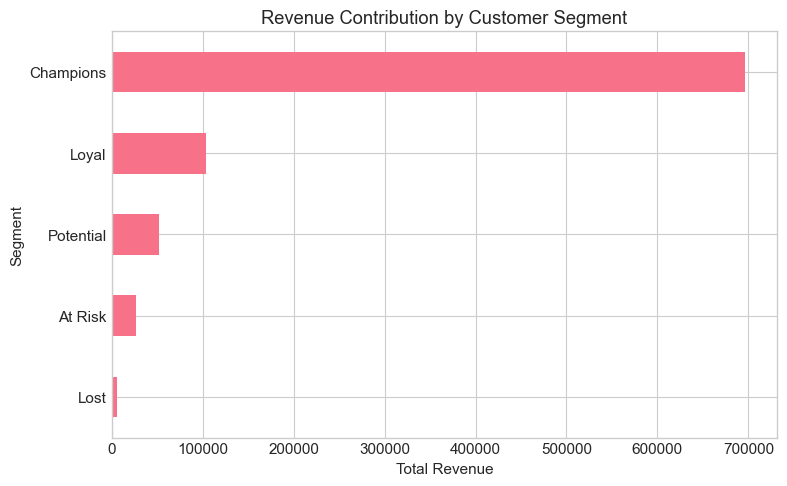

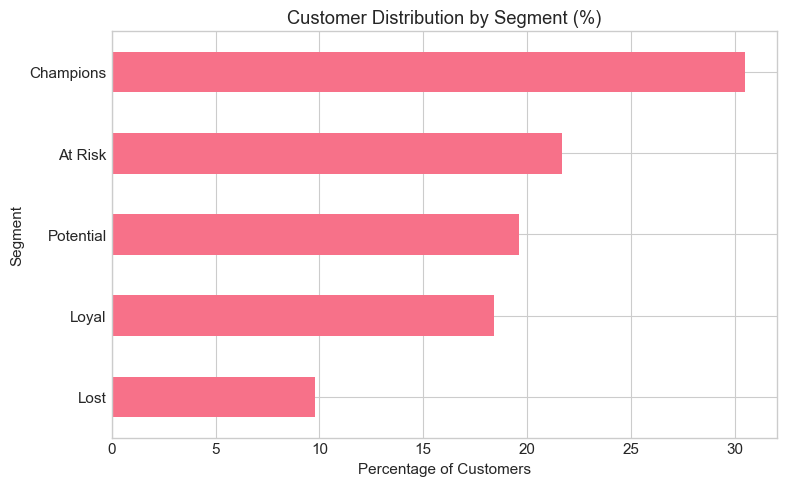

In [9]:
# ============================================================
# SEGMENT PERFORMANCE VISUALIZATION (Executive Version)
# ============================================================

plt.figure(figsize=(8,5))

# Revenue by segment (most important metric)
segment_analysis['Total_Revenue'] \
    .sort_values() \
    .plot(kind='barh')

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Total Revenue")
plt.ylabel("Segment")
plt.tight_layout()
plt.savefig(FIGURES_PATH / 'segment_revenue_bar.png', dpi=300)
plt.show()


# ------------------------------------------------------------
# Customer Distribution
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

segment_analysis['Pct_Customers'] \
    .sort_values() \
    .plot(kind='barh')

plt.title("Customer Distribution by Segment (%)")
plt.xlabel("Percentage of Customers")
plt.ylabel("Segment")
plt.tight_layout()
plt.savefig(FIGURES_PATH / 'segment_customer_distribution.png', dpi=300)
plt.show()

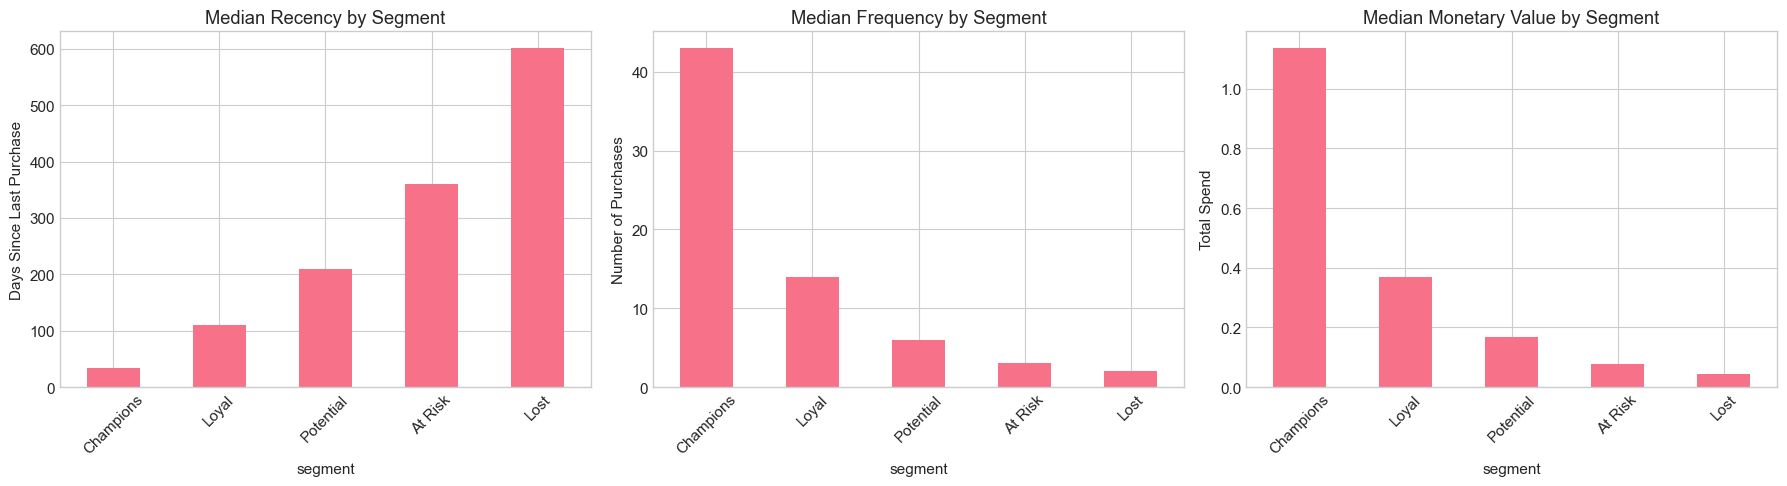

In [10]:
# ============================================================
# RFM PROFILE BY SEGMENT (Cleaner Executive Version)
# ============================================================

rfm_summary = (
    rfm.groupby('segment')
    .agg(
        Median_Recency=('recency', 'median'),
        Median_Frequency=('frequency', 'median'),
        Median_Monetary=('monetary', 'median')
    )
)

segment_order = ['Champions', 'Loyal', 'Potential', 'At Risk', 'Lost']
rfm_summary = rfm_summary.reindex(segment_order)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Recency
rfm_summary['Median_Recency'].plot(kind='bar', ax=axes[0])
axes[0].set_title('Median Recency by Segment')
axes[0].set_ylabel('Days Since Last Purchase')
axes[0].tick_params(axis='x', rotation=45)

# Frequency
rfm_summary['Median_Frequency'].plot(kind='bar', ax=axes[1])
axes[1].set_title('Median Frequency by Segment')
axes[1].set_ylabel('Number of Purchases')
axes[1].tick_params(axis='x', rotation=45)

# Monetary
rfm_summary['Median_Monetary'].plot(kind='bar', ax=axes[2])
axes[2].set_title('Median Monetary Value by Segment')
axes[2].set_ylabel('Total Spend')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(FIGURES_PATH / 'rfm_segment_profiles.png', dpi=300)
plt.show()

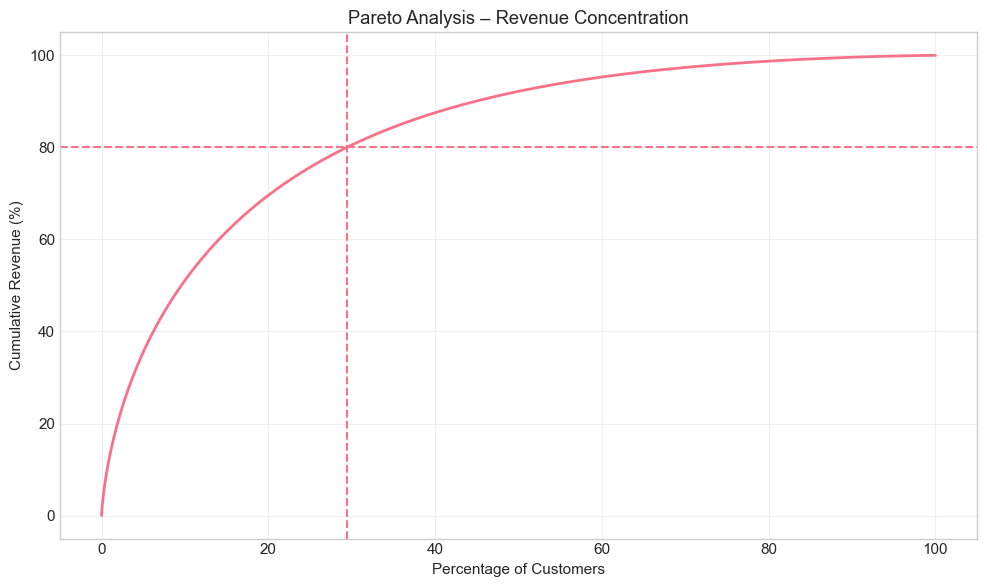


Pareto Principle Validation:
Top 29.41% of customers generate 80% of revenue


In [11]:
# ============================================================
# PARETO ANALYSIS (Customer Revenue Concentration)
# ============================================================

customers_sorted = (
    rfm.sort_values('monetary', ascending=False)
       .reset_index(drop=True)
)

customers_sorted['cumulative_revenue'] = customers_sorted['monetary'].cumsum()
customers_sorted['cumulative_pct'] = (
    customers_sorted['cumulative_revenue'] /
    customers_sorted['monetary'].sum() * 100
)

customers_sorted['customer_pct'] = (
    (customers_sorted.index + 1) /
    len(customers_sorted) * 100
)

# Find first point where cumulative revenue exceeds 80%
pct_customers_80 = customers_sorted.loc[
    customers_sorted['cumulative_pct'] >= 80,
    'customer_pct'
].iloc[0]

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10,6))

# Cumulative revenue %
ax.plot(customers_sorted['customer_pct'],
        customers_sorted['cumulative_pct'],
        linewidth=2)

ax.axhline(80, linestyle='--')
ax.axvline(pct_customers_80, linestyle='--')

ax.set_xlabel("Percentage of Customers")
ax.set_ylabel("Cumulative Revenue (%)")
ax.set_title("Pareto Analysis – Revenue Concentration")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_PATH / 'rfm_pareto.png', dpi=300)
plt.show()

print("\nPareto Principle Validation:")
print(f"Top {pct_customers_80:.2f}% of customers generate 80% of revenue")

In [12]:
# ============================================================
# DETAILED SEGMENT PROFILES
# ============================================================

print("\nDETAILED SEGMENT PROFILES")
print("="*80)

total_revenue = rfm['monetary'].sum()
total_customers = len(rfm)

for segment in segment_order:

    segment_data = rfm[rfm['segment'] == segment]

    seg_count = len(segment_data)
    seg_pct = seg_count / total_customers * 100
    seg_revenue = segment_data['monetary'].sum()
    seg_rev_pct = seg_revenue / total_revenue * 100

    print(f"\n{segment.upper()}")
    print("-" * 50)

    print(f"Size: {seg_count:,} customers ({seg_pct:.1f}%)")
    print(f"Revenue Contribution: {seg_revenue:,.2f} ({seg_rev_pct:.1f}%)")

    print("\nBehavioral Characteristics:")
    print(f"  • Avg Recency: {segment_data['recency'].mean():.0f} days")
    print(f"  • Avg Frequency: {segment_data['frequency'].mean():.1f} purchases")
    print(f"  • Avg Monetary Value: {segment_data['monetary'].mean():,.2f}")
    print(f"  • Median Monetary Value: {segment_data['monetary'].median():,.2f}")


DETAILED SEGMENT PROFILES

CHAMPIONS
--------------------------------------------------
Size: 415,925 customers (30.5%)
Revenue Contribution: 696,633.39 (78.7%)

Behavioral Characteristics:
  • Avg Recency: 58 days
  • Avg Frequency: 59.4 purchases
  • Avg Monetary Value: 1.67
  • Median Monetary Value: 1.14

LOYAL
--------------------------------------------------
Size: 251,271 customers (18.4%)
Revenue Contribution: 104,067.26 (11.8%)

Behavioral Characteristics:
  • Avg Recency: 152 days
  • Avg Frequency: 15.6 purchases
  • Avg Monetary Value: 0.41
  • Median Monetary Value: 0.37

POTENTIAL
--------------------------------------------------
Size: 266,556 customers (19.6%)
Revenue Contribution: 51,866.05 (5.9%)

Behavioral Characteristics:
  • Avg Recency: 254 days
  • Avg Frequency: 7.3 purchases
  • Avg Monetary Value: 0.19
  • Median Monetary Value: 0.17

AT RISK
--------------------------------------------------
Size: 295,502 customers (21.7%)
Revenue Contribution: 26,263.61 (3

In [13]:
# ============================================================
# DATA-DRIVEN BUSINESS RECOMMENDATIONS
# ============================================================

print("\nBUSINESS RECOMMENDATIONS BY SEGMENT")
print("="*80)

total_revenue = rfm['monetary'].sum()

for segment in segment_order:

    seg_data = rfm[rfm['segment'] == segment]
    seg_count = len(seg_data)
    seg_revenue = seg_data['monetary'].sum()
    seg_rev_pct = seg_revenue / total_revenue * 100

    print(f"\n{segment.upper()}")
    print("-" * 50)
    print(f"Segment Size: {seg_count:,} customers")
    print(f"Revenue Contribution: {seg_rev_pct:.1f}%")

    if segment == 'Champions':
        print("\nStrategy: Protect high-value base")
        print("Actions:")
        print("  • VIP loyalty programs")
        print("  • Early product access")
        print("  • Personalized premium offers")
        print("Business Rationale:")
        print("  • Small segment driving large revenue share")
        print("  • Retention here protects core revenue stream")

    elif segment == 'Loyal':
        print("\nStrategy: Upgrade to Champions")
        print("Actions:")
        print("  • Targeted cross-sell campaigns")
        print("  • Reward frequency growth")
        print("Business Rationale:")
        print("  • High engagement, moderate spend")
        print("  • Strong upsell opportunity")

    elif segment == 'Potential':
        print("\nStrategy: Increase purchase frequency")
        print("Actions:")
        print("  • Product bundles")
        print("  • Time-bound offers")
        print("Business Rationale:")
        print("  • Medium value customers")
        print("  • Growth opportunity segment")

    elif segment == 'At Risk':
        print("\nStrategy: Prevent churn")
        print("Actions:")
        print("  • Win-back campaigns")
        print("  • Personalized incentives")
        print("Business Rationale:")
        print("  • Previously active but declining recency")
        print("  • Revenue exposure risk")

    elif segment == 'Lost':
        print("\nStrategy: Selective reactivation")
        print("Actions:")
        print("  • Limited reactivation campaign")
        print("  • Feedback surveys")
        print("Business Rationale:")
        print("  • Low engagement")
        print("  • High acquisition cost vs recovery trade-off")


BUSINESS RECOMMENDATIONS BY SEGMENT

CHAMPIONS
--------------------------------------------------
Segment Size: 415,925 customers
Revenue Contribution: 78.7%

Strategy: Protect high-value base
Actions:
  • VIP loyalty programs
  • Early product access
  • Personalized premium offers
Business Rationale:
  • Small segment driving large revenue share
  • Retention here protects core revenue stream

LOYAL
--------------------------------------------------
Segment Size: 251,271 customers
Revenue Contribution: 11.8%

Strategy: Upgrade to Champions
Actions:
  • Targeted cross-sell campaigns
  • Reward frequency growth
Business Rationale:
  • High engagement, moderate spend
  • Strong upsell opportunity

POTENTIAL
--------------------------------------------------
Segment Size: 266,556 customers
Revenue Contribution: 5.9%

Strategy: Increase purchase frequency
Actions:
  • Product bundles
  • Time-bound offers
Business Rationale:
  • Medium value customers
  • Growth opportunity segment

AT R

In [14]:
# ============================================================
# SCENARIO-BASED BUSINESS IMPACT ESTIMATION
# ============================================================

print("\nSCENARIO-BASED REVENUE IMPACT")
print("="*80)

current_revenue = rfm['monetary'].sum()

scenarios = {
    "Conservative": 0.05,
    "Moderate": 0.12,
    "Aggressive": 0.20
}

results = []

for name, uplift in scenarios.items():

    additional_revenue = current_revenue * uplift
    marketing_investment = additional_revenue * 0.10   # assume 10% reinvestment
    net_impact = additional_revenue - marketing_investment
    roi = (net_impact / marketing_investment) * 100

    results.append([
        name,
        uplift * 100,
        additional_revenue,
        marketing_investment,
        net_impact,
        roi
    ])

roi_df = pd.DataFrame(results, columns=[
    "Scenario",
    "Revenue Uplift (%)",
    "Additional Revenue",
    "Marketing Investment",
    "Net Impact",
    "ROI (%)"
])

display(roi_df)

roi_df.to_csv(TABLES_PATH / "roi_scenarios.csv", index=False)
print("\nSaved: reports/tables/roi_scenarios.csv")


SCENARIO-BASED REVENUE IMPACT


,Scenario,Revenue Uplift (%),Additional Revenue,Marketing Investment,Net Impact,ROI (%)
0,Conservative,5.00,44232.30,4423.23,39809.07,900.00
1,Moderate,12.00,106157.52,10615.75,95541.77,900.00
2,Aggressive,20.00,176929.19,17692.92,159236.28,900.00



Saved: reports/tables/roi_scenarios.csv


In [15]:
# ============================================================
# SAVE RFM FEATURES FOR ML PIPELINE
# ============================================================

print("\nSaving RFM features for downstream ML models...")

# Binary target: High-value customers
rfm['high_value'] = rfm['segment'].isin(['Champions', 'Loyal']).astype(int)

# Optional ordinal encoding
segment_mapping = {
    'Lost': 1,
    'At Risk': 2,
    'Potential': 3,
    'Loyal': 4,
    'Champions': 5
}
rfm['segment_encoded'] = rfm['segment'].map(segment_mapping)

# Feature selection for ML
ml_features = rfm[
    ['customer_id', 'recency', 'frequency', 'monetary',
     'R_score', 'F_score', 'M_score',
     'segment', 'segment_encoded', 'high_value']
]

# Save parquet (efficient)
ml_features.to_parquet(FEATURES_PATH / 'rfm_features.parquet', index=False)

# Save CSV (readable)
ml_features.to_csv(FEATURES_PATH / 'rfm_features.csv', index=False)

print(f"Saved: data/features/rfm_features.parquet")
print(f"Saved: data/features/rfm_features.csv")
print(f"\nTotal customers saved: {len(ml_features):,}")


Saving RFM features for downstream ML models...
Saved: data/features/rfm_features.parquet
Saved: data/features/rfm_features.csv

Total customers saved: 1,362,281


In [16]:
print("\n" + "="*80)
print("CUSTOMER SEGMENTATION ANALYSIS COMPLETED")
print("="*80)

print(f"\nDataset Scope:")
print(f"  • {len(rfm):,} unique customers analyzed")
print(f"  • 5 behavioral segments identified using RFM methodology")

print(f"\nRevenue Concentration Insight:")
print(f"  • Top {pct_customers_80:.1f}% of customers generate 80% of total revenue")

print(f"\nStrategic Outcomes:")
print(f"  • High-value segments isolated for targeted retention")
print(f"  • At-Risk customers identified for churn prevention")
print(f"  • Scenario-based revenue uplift modeled")

print(f"\nAssets Generated:")
print(f"  • Segmentation tables and KPI summaries")
print(f"  • Revenue concentration (Pareto) analysis")
print(f"  • ML-ready feature dataset")

print("\nNext Phase:")
print("  → Build predictive model for high-value customer identification")
print("  → Deploy model insights into business decision framework")

print("\n" + "="*80)


CUSTOMER SEGMENTATION ANALYSIS COMPLETED

Dataset Scope:
  • 1,362,281 unique customers analyzed
  • 5 behavioral segments identified using RFM methodology

Revenue Concentration Insight:
  • Top 29.4% of customers generate 80% of total revenue

Strategic Outcomes:
  • High-value segments isolated for targeted retention
  • At-Risk customers identified for churn prevention
  • Scenario-based revenue uplift modeled

Assets Generated:
  • Segmentation tables and KPI summaries
  • Revenue concentration (Pareto) analysis
  • ML-ready feature dataset

Next Phase:
  → Build predictive model for high-value customer identification
  → Deploy model insights into business decision framework

